In [4]:
import torch
from torch.utils.data import DataLoader, TensorDataset, Dataset
import pandas as pd
import numpy as np

from esm import FastaBatchedDataset, pretrained

In [5]:
dataset = pd.read_csv("data/c_test.csv")
dataset["id"] = ["protein"+str(i) for i in dataset.index]

cleavage_seqs = dataset[["elution_cleavage","cleavage_window"]].iloc[:10000].to_records(index=False)

In [6]:
model_name = 'esm2_t33_650M_UR50D'
seq_length=1022

In [8]:
model, alphabet = pretrained.load_model_and_alphabet(model_name)
model.eval()  # disables dropout for deterministic results
model.half()

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE is not None:
    model = model.to(DEVICE)



In [9]:
batch_converter = alphabet.get_batch_converter(truncation_seq_length=seq_length)
batch_labels, batch_strs, batch_tokens = batch_converter(cleavage_seqs)
# Convert batch_labels to a tensor
batch_labels = torch.tensor(batch_labels) 
batch_lens = (batch_tokens != alphabet.padding_idx).sum(1)

In [28]:
results.keys()

dict_keys(['logits', 'representations', 'attentions', 'contacts'])

In [ ]:
with torch.no_grad():
    results = model(batch_tokens.to(DEVICE), repr_layers=[33], return_contacts=True,)
token_representations = results["representations"][33]

In [8]:
# Generate per-sequence representations via averaging
# NOTE: token 0 is always a beginning-of-sequence token, so the first residue is token 1. Token 2 is eos

sequence_representations = []
for i, tokens_len in enumerate(batch_lens):
    sequence_representations.append(token_representations[i, 1 : tokens_len - 1].mean(0))


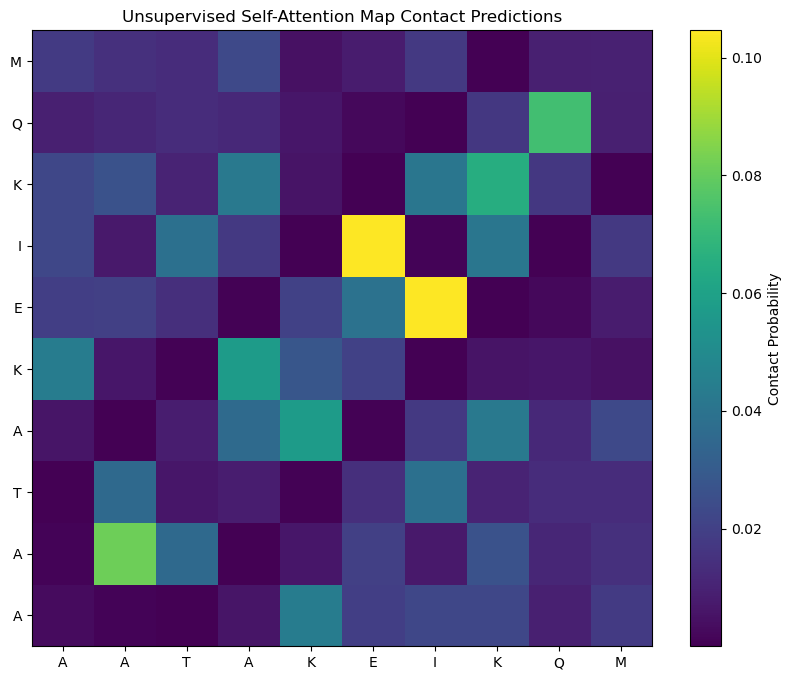

In [19]:
# Look at the unsupervised self-attention map contact predictions
import matplotlib.pyplot as plt
for (_, seq), tokens_len, attention_contacts in zip(cleavage_seqs, batch_lens, results["contacts"]):
    attention_contacts = attention_contacts.cpu()
    # plt.matshow(attention_contacts[: tokens_len, : tokens_len])
    # plt.title(seq)
    # plt.show()
    residue_labels = list(seq)
    # Plot contact map
    plt.figure(figsize=(10, 8))
    plt.imshow(attention_contacts, cmap='viridis', origin='lower', aspect='auto')
    plt.colorbar(label='Contact Probability')
    plt.xticks(range(len(residue_labels)), residue_labels)
    plt.yticks(range(len(residue_labels)), residue_labels)
    plt.title('Unsupervised Self-Attention Map Contact Predictions')
    plt.show()

    break

## Obtain embedding using ESM package ,TensorDataset and DataLoeader to manage different batch sizes. Working

In [4]:
import torch
from torch.utils.data import DataLoader, TensorDataset, Dataset
import pandas as pd
from esm import pretrained

In [5]:
dataset = pd.read_csv("data/c_test.csv")
dataset["id"] = ["protein"+str(i) for i in dataset.index]

cleavage_seqs = dataset[["elution_cleavage","cleavage_window"]].iloc[:1000].to_records(index=False)

In [7]:
model_name = 'esm2_t33_650M_UR50D'
seq_length=1022

In [8]:
model, alphabet = pretrained.load_model_and_alphabet(model_name)
model.eval()  # disables dropout for deterministic results

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE is not None:
    model = model.to(DEVICE)

batch_converter = alphabet.get_batch_converter(truncation_seq_length=seq_length)
batch_labels, batch_strs, batch_tokens = batch_converter(cleavage_seqs)
# Convert batch_labels to a tensor
batch_labels = torch.tensor(batch_labels) 
batch_lens = (batch_tokens != alphabet.padding_idx).sum(1)




dataset = TensorDataset(batch_tokens, batch_labels)
batch_size = 32
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=False, pin_memory=True)

token_representations = []
for batch_tokens, _ in dataloader:  # We don't need labels here
    batch_tokens = batch_tokens.to(DEVICE)
    with torch.no_grad():
        results = model(batch_tokens, repr_layers=[33], return_contacts=True)
        token_representations.append(results["representations"][33])

# Combine all token representations
token_representations = torch.cat(token_representations, dim=0)

In [9]:
token_representations.size()

torch.Size([1000, 12, 1280])

## embedding using Hugging Face transformer package and pipeline. V1 wrking but not optimal

In [4]:
import torch
from torch.utils.data import DataLoader, TensorDataset, Dataset
from transformers import pipeline, AutoTokenizer,EsmForMaskedLM
import pandas as pd


In [2]:
df_test = pd.read_csv("data/c_test.csv").iloc[:1000]

In [3]:
model_name = 'esm2_t33_650M_UR50D'
seq_length=1022

In [4]:
# Load the ESM-2 model and tokenizer for feature extraction
model_name = "facebook/esm2_t33_650M_UR50D"
tokenizer = AutoTokenizer.from_pretrained(model_name,max_length=seq_length)
model = EsmForMaskedLM.from_pretrained(model_name)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
pipe = pipeline("feature-extraction", model=model, tokenizer=tokenizer, device=DEVICE) 

class PeptideDataset(Dataset):
    def __init__(self, df):
        self.sequences = df['cleavage_window'].tolist()
        self.labels = df['elution_cleavage'].tolist()

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        sequence = self.sequences[idx]
        label = self.labels[idx]
        return sequence, label  # Return sequence and label directly


# Create the dataset and dataloader
dataset = PeptideDataset(df_test)
dataloader = DataLoader(dataset, batch_size=32, shuffle=False,pin_memory=True)  # Adjust batch size as needed

# Tokenization and Embedding Extraction (outside of the dataset class)
embeddings = []
labels = []
for batch_sequences, batch_labels in dataloader:
    #tokenized_batch = tokenizer(batch_sequences, return_tensors="pt", padding=True, truncation=True)
    batch_embeddings = pipe(batch_sequences)  # Ensure batch is on the same device as the pipeline
    embeddings.extend(batch_embeddings)
    labels.extend(batch_labels)




You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


## embedding using Hugging Face transformer package and pipeline. V2

In [1]:
import torch
from torch.utils.data import DataLoader, TensorDataset, Dataset
from transformers import AutoTokenizer,EsmModel, AutoModel
import pandas as pd
from pathlib import Path

In [2]:
%%time
df_test = pd.read_csv("data/c_test.csv").iloc[:10000]

model_name = 'esm2_t33_650M_UR50D'
seq_length=1022
batch_size=32 # same as extract script from fair_esm

CPU times: user 59.1 ms, sys: 23.5 ms, total: 82.6 ms
Wall time: 125 ms


In [3]:
%%time

# Load the ESM-2 model and tokenizer for feature extraction
model_name = "facebook/esm2_t33_650M_UR50D"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = EsmModel.from_pretrained(model_name)

model.half()
model.eval()

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE is not None:
    model = model.to(DEVICE)

class PeptideDataset(Dataset):
    def __init__(self, df):
        self.sequences = df['cleavage_window'].tolist()
        self.labels = df['elution_cleavage'].tolist()

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        sequence = self.sequences[idx]
        label = self.labels[idx]
        return sequence, label  # Return sequence and label directly


# Create the dataset and dataloader
dataset = PeptideDataset(df_test)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=False,pin_memory=True,num_workers=5)  # Adjust batch size as needed


token_representations = []
for batch_sequences, _ in dataloader:  # We don't need labels here
    batch_tokens = tokenizer(batch_sequences, return_tensors="pt", padding=True, truncation=True, max_length=seq_length).to(DEVICE)
    with torch.no_grad():
        results = model(**batch_tokens)
        token_representations.append(results.last_hidden_state)
# Combine all token representations
#token_representations = torch.cat(token_representations, dim=0)

Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t33_650M_UR50D and are newly initialized: ['esm.pooler.dense.bias', 'esm.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


KeyboardInterrupt: 

### same as before but processing dataframe by chunks for memory problems

In [3]:
%%time


outdir = Path("data/embeddings")
if not outdir.is_dir():
    outdir.mkdir()
    
# Load the ESM-2 model and tokenizer for feature extraction
model_name = "facebook/esm2_t33_650M_UR50D"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = EsmModel.from_pretrained(model_name)

model.half()
model.eval()

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE is not None:
    model = model.to(DEVICE)

class PeptideDataset(Dataset):
    def __init__(self, df):
        self.sequences = df['cleavage_window'].tolist()
        self.labels = df['elution_cleavage'].tolist()

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        sequence = self.sequences[idx]
        label = self.labels[idx]
        return sequence, label  # Return sequence and label directly


# Function to process a chunk of data
def process_chunk(df_chunk, model, tokenizer, device):
    dataset = PeptideDataset(df_chunk)
    dataloader = DataLoader(dataset, batch_size=32, shuffle=False, pin_memory=True, num_workers=5)
    
    token_representations = []
    for batch_sequences, _ in dataloader:
        batch_tokens = tokenizer(batch_sequences, return_tensors="pt", padding=True, truncation=True, max_length=seq_length).to(device)
        with torch.no_grad():
            results = model(**batch_tokens)
            token_representations.append(results.last_hidden_state)
    token_representations = torch.cat(token_representations, dim=0)
    return token_representations

# Main processing loop
chunk_size = 10000  # Adjust chunk size based on available RAM
all_token_representations = []
for i in range(0, len(df_test), chunk_size):
    df_chunk = df_test.iloc[i : i + chunk_size]
    chunk_representations = process_chunk(df_chunk, model, tokenizer, DEVICE)
    torch.save(chunk_representations,outdir/f"test_emb_chunk{i}.pt")
    all_token_representations.extend(chunk_representations)
    del chunk_representations

# Combine results and post-process if needed
all_token_representations = torch.cat(all_token_representations, dim=0) 
# ... Further processing on all_token_representations



Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t33_650M_UR50D and are newly initialized: ['esm.pooler.dense.bias', 'esm.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


CPU times: user 12min 18s, sys: 1min 31s, total: 13min 49s
Wall time: 12min 58s


### embedding using Hugging Face transformer package and pipeline. V3

In [1]:
import torch
from torch.utils.data import DataLoader, TensorDataset, Dataset
from transformers.pipelines.pt_utils import KeyDataset
from transformers import pipeline, AutoTokenizer,EsmModel
from pathlib import Path

from datasets import load_dataset

outdir = Path("data/embeddings")
if not outdir.is_dir():
    outdir.mkdir()


In [2]:
df_test = load_dataset("csv",data_files="data/c_test.csv",split="train[:50%]")

model_name = 'esm2_t33_650M_UR50D'
seq_length=1022

In [7]:
df_test

Dataset({
    features: ['cleavage_window', 'elution_cleavage'],
    num_rows: 70975
})

In [4]:
%%time
batch_size = 32

# Load the ESM-2 model and tokenizer for feature extraction
model_name = "facebook/esm2_t33_650M_UR50D"
tokenizer = AutoTokenizer.from_pretrained(model_name,max_length=seq_length)
model = EsmModel.from_pretrained(model_name,device_map='auto',torch_dtype="auto")
#model.half()
model.eval()

#DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


pipe = pipeline("feature-extraction", model=model, tokenizer=tokenizer) 


result_embeddings = []
for out in pipe(KeyDataset(df_test,'cleavage_window'),batch_size=batch_size,return_tensors=True,num_workers=10):
    result_embeddings.append(out)
all_embeddings = torch.cat(result_embeddings, dim=0)
torch.save(all_embeddings,outdir/f"test_emb_{df_test.shape[0]}seqs.pt")

Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t33_650M_UR50D and are newly initialized: ['esm.pooler.dense.bias', 'esm.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


CPU times: user 10min 35s, sys: 1min 11s, total: 11min 47s
Wall time: 12min 12s


In [6]:
all_embeddings.shape

torch.Size([70975, 12, 1280])

In [ ]:
%%time

batch_size = 32

# Load the ESM-2 model and tokenizer for feature extraction
model_name = "facebook/esm2_t33_650M_UR50D"
tokenizer = AutoTokenizer.from_pretrained(model_name,max_length=seq_length)
model = EsmModel.from_pretrained(model_name,device_map='auto',torch_dtype="auto")
#model.half()
model.eval()

#DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


pipe = pipeline("feature-extraction", model=model, tokenizer=tokenizer) 


# Define a function to process each batch
def process_batch(batch):
    embeddings = pipe(batch["cleavage_window"], batch_size=batch_size, return_tensors=True)
    return {"embeddings": embeddings}

# Apply the pipeline in batches using the map function
result_dataset = df_test.map(
    process_batch,
    batched=True,  # Process in batches
    batch_size=batch_size,
    writer_batch_size=batch_size,
    remove_columns=['cleavage_window'],  # Remove original column to save memory
)

# Concatenate the embeddings
all_embeddings = torch.cat([x["embeddings"] for x in result_dataset], dim=0)

Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t33_650M_UR50D and are newly initialized: ['esm.pooler.dense.bias', 'esm.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/42585 [00:00<?, ? examples/s]

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


## T-SNE Visualization of Sequence Embeddings

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

import openTSNE
import pandas as pd

import torch
from datasets import load_dataset

In [34]:
df_test = load_dataset("csv",data_files="data/c_test.csv",split="train[:30%]")

In [53]:
df_test[:10]

{'cleavage_window': ['AATAKEIKQM',
  'KASEVFLQRL',
  'HRSTLQPSLQ',
  'ETDLSFKKGE',
  'GTMARKLRYT',
  'QGLKCDGCGL',
  'FTAPSTVGKR',
  'LAFHDISPQA',
  'TAFGGWKSVE',
  'AYKEAFEISK'],
 'elution_cleavage': [0, 0, 0, 0, 0, 0, 0, 0, 1, 1]}

In [5]:
all_embeddings = torch.load('data/embeddings/test_emb_42585seqs.pt')
# Generate per-sequence representations via averaging
# NOTE: token 0 is always a beginning-of-sequence token, so the first residue is token 1. Token 2 is eos

seqs_embedding =  all_embeddings[:,1:-1,:].mean(1)

In [47]:
embedding_annealing = openTSNE.TSNE(
    perplexity=500, metric="cosine", initialization="pca", n_jobs=8, random_state=3,exaggeration=4
).fit(seqs_embedding)

In [46]:
openTSNE.TSNE?

Init signature:
openTSNE.TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    early_exaggeration_iter=250,
    early_exaggeration='auto',
    n_iter=500,
    exaggeration=None,
    dof=1,
    theta=0.5,
    n_interpolation_points=3,
    min_num_intervals=50,
    ints_in_interval=1,
    initialization='pca',
    metric='euclidean',
    metric_params=None,
    initial_momentum=0.8,
    final_momentum=0.8,
    max_grad_norm=None,
    max_step_norm=5,
    n_jobs=1,
    neighbors='auto',
    negative_gradient_method='auto',
    callbacks=None,
    callbacks_every_iters=50,
    random_state=None,
    verbose=False,
)
Docstring:     
t-Distributed Stochastic Neighbor Embedding.

Please see the :ref:`parameter-guide` for more information.

Parameters
----------
n_components: int
    The dimension of the embedding space. This deafults to 2 for easy
    visualization, but sometimes 1 is used for t-SNE heatmaps. t-SNE is
    not designed to embed into higher dimension and pl

In [49]:
embedding_annealing.affinities.set_perplexities([50])
embedding_annealing_opt = embedding_annealing.optimize(250)

In [39]:
embedding_pca_cosine = openTSNE.TSNE(
    perplexity=10,
    initialization="random",
    metric="cosine",
    n_jobs=8,
    random_state=3,
    it
    verbose=True
).fit(seqs_embedding)




--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, initialization='random', metric='cosine', n_jobs=8,
     random_state=3, verbose=True)
--------------------------------------------------------------------------------
===> Finding 90 nearest neighbors using Annoy approximate search using cosine distance...
   --> Time elapsed: 130.33 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 0.48 seconds
===> Running optimization with exaggeration=12.00, lr=3548.75 for 250 iterations...
Iteration   50, KL divergence 6.9815, 50 iterations in 1.4173 sec
Iteration  100, KL divergence 6.8699, 50 iterations in 1.4588 sec
Iteration  150, KL divergence 6.8708, 50 iterations in 1.4242 sec
Iteration  200, KL divergence 6.8708, 50 iterations in 1.4127 sec
Iteration  250, KL divergence 6.8708, 50 iterations in 1.4235 sec
   --> Time elapsed: 7.14 seconds
===> Running optimization with exaggeration=1.00, lr=42585.00 for 500 iteration

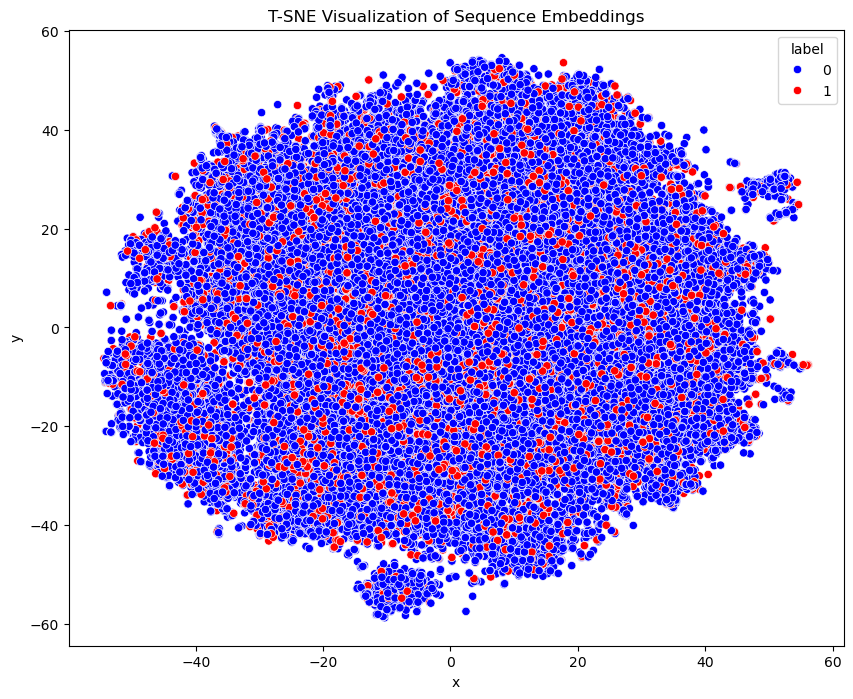

In [50]:
# Load the labels 
labels = df_test["elution_cleavage"]  

# Create a DataFrame for plotting
df_plot = pd.DataFrame({
    "x": embedding_annealing_opt[:, 0],
    "y": embedding_annealing_opt[:, 1],
    "label": labels  
})

# Create the T-SNE plot using Seaborn
plt.figure(figsize=(10, 8))
sns.scatterplot(data=df_plot, x="x", y="y", hue="label", palette=["blue", "red"])  # Customize colors
plt.title("T-SNE Visualization of Sequence Embeddings")
plt.show()